<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [106]:
import random

In [107]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [108]:
len(l)

10000

In [109]:
l[:5]

[8, 7, 9, 9, 7]

In [110]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0275
3     0.0561
4     0.0827
5     0.1078
6     0.1429
7     0.1676
8     0.1398
9     0.1076
10    0.0827
11    0.0583
12    0.0270
Name: count, dtype: float64


<Axes: >

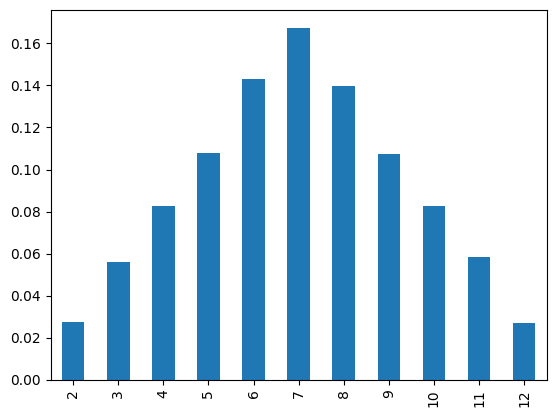

In [111]:
s.plot(kind='bar')

<Axes: >

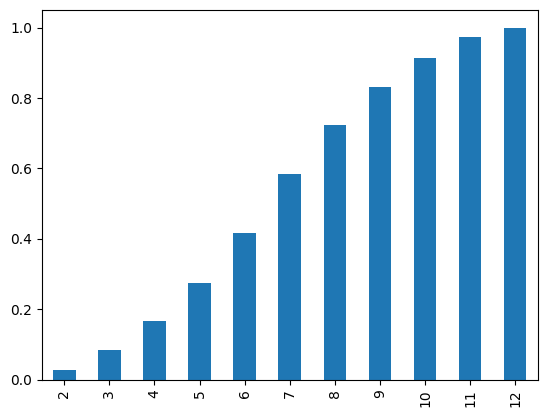

In [112]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [113]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[47.18819335 49.03912169 50.80413281 52.73451902 56.89892496 46.7698241
 50.97293752 56.14396352 48.48854411 51.27741681 48.40615193 44.52259394
 55.59818582 54.58851419 49.51825218 50.56906811 40.42531675 47.35592947
 47.57708807 49.8636499  56.58620501 41.37359285 55.65617476 57.15953166
 47.95101745 53.36771899 49.22937404 58.82204106 60.35481618 55.91551425
 60.40861172 57.97718272 52.73080437 42.0629046  51.60065921 53.81515816
 61.80198364 58.06273304 50.11169999 47.89927483 50.53575098 49.50228166
 57.23087436 48.68844621 52.01642464 59.34558122 56.52344888 55.82571991
 52.26804189 56.97761463 46.72824518 42.15137983 46.81353551 47.34130564
 54.48037471 53.06457471 50.53808817 47.71363873 43.06366102 43.80518048
 54.56009816 48.23255667 46.41167493 50.74757226 47.15059462 48.86522272
 48.75938835 50.9192966  53.53175973 41.86415658 48.25482199 55.37996251
 58.91147569 43.52522697 59.93085894 52.35886038 53.56722339 48.36825032
 41.5620491  49.00637816 55.7775486  43.63782433 41.

In [114]:
sample.mean()

np.float64(49.842438351119284)

(array([  3.,  26.,  71., 149., 243., 228., 167.,  78.,  27.,   8.]),
 array([34.69321093, 37.6867826 , 40.68035428, 43.67392595, 46.66749763,
        49.66106931, 52.65464098, 55.64821266, 58.64178434, 61.63535601,
        64.62892769]),
 <BarContainer object of 10 artists>)

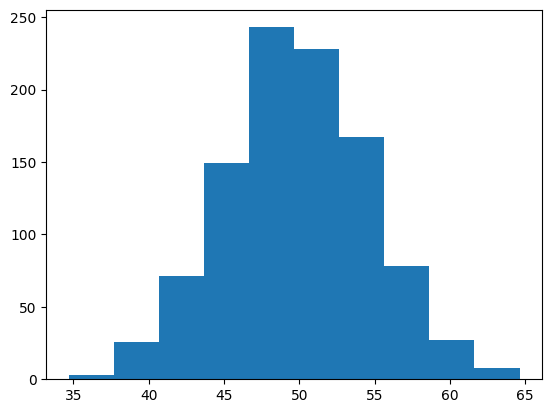

In [115]:
plt.hist(sample,bins=10)

In [116]:
sample_mean=sample.mean()
sample_std=sample.std()

In [117]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [118]:
sample.min()

np.float64(34.69321092537419)

In [119]:
sample.max()

np.float64(64.62892768772065)

In [120]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [121]:
probabilities=[dist.pdf(value) for value in values]

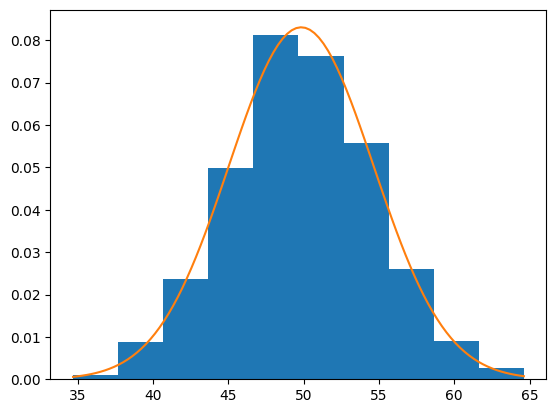

In [122]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_4240/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

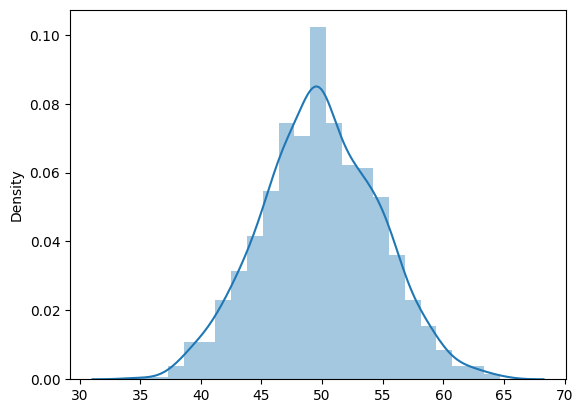

In [123]:
import seaborn as sns
sns.distplot(sample)

KDE

In [124]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [125]:
sample

array([25.28149151, 21.8133072 , 25.35873691, 15.77587353, 19.50178393,
       25.97720755,  9.44124054, 20.44187061, 14.14467569, 26.8850146 ,
       20.66074489, 16.41026404, 21.6916028 , 28.96599806, 28.27931833,
       18.52099363, 18.9256625 , 18.45141536, 29.25202905, 22.52723806,
       26.19793914, 21.66297605, 22.80712244, 16.18035683, 22.45970575,
       13.73019936, 14.52207817, 13.65158229, 16.62521508, 24.9069726 ,
       15.56332   , 18.42464069, 13.72824653, 27.04490464, 23.10985571,
       18.32460559, 24.53073904, 18.58728447, 12.65542064, 18.54644919,
       22.80850275, 19.91450458, 18.9675034 , 23.33728508, 16.76683059,
       20.65287827,  3.33134898, 24.74135849, 22.64573873, 19.15576099,
       22.8354153 , 18.57392514, 22.59273375, 18.01279513, 10.31940582,
       18.95769227,  6.74559223, 19.12765349, 13.46639423, 18.05283125,
       32.24062382, 19.3371753 , 17.81211525, 15.73774981, 22.94212612,
       18.83727487, 22.087648  , 21.27159761,  9.69473951, 15.55

(array([ 1.,  2.,  1.,  1.,  0.,  4.,  5.,  3.,  3.,  6., 13.,  9., 20.,
        13., 24., 33., 25., 18., 17., 33.,  9., 12., 11., 20., 11.,  7.,
         8., 17., 25., 15., 27., 28., 35., 54., 52., 54., 58., 61., 65.,
        50., 36., 26., 30., 11., 16., 12.,  5.,  7.,  5.,  2.]),
 array([ 3.33134898,  4.33204156,  5.33273415,  6.33342673,  7.33411931,
         8.33481189,  9.33550447, 10.33619705, 11.33688963, 12.33758222,
        13.3382748 , 14.33896738, 15.33965996, 16.34035254, 17.34104512,
        18.3417377 , 19.34243029, 20.34312287, 21.34381545, 22.34450803,
        23.34520061, 24.34589319, 25.34658577, 26.34727836, 27.34797094,
        28.34866352, 29.3493561 , 30.35004868, 31.35074126, 32.35143384,
        33.35212643, 34.35281901, 35.35351159, 36.35420417, 37.35489675,
        38.35558933, 39.35628191, 40.3569745 , 41.35766708, 42.35835966,
        43.35905224, 44.35974482, 45.3604374 , 46.36112998, 47.36182257,
        48.36251515, 49.36320773, 50.36390031, 51.36459289,

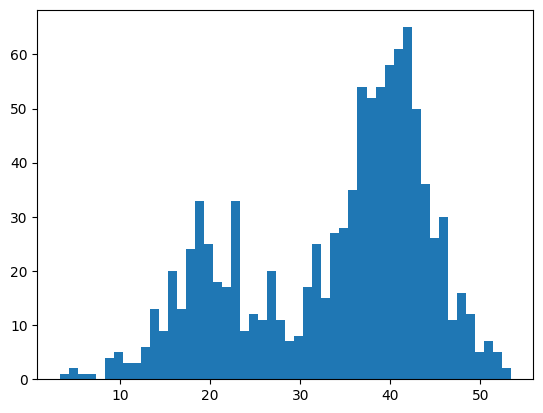

In [126]:
plt.hist(sample,bins=50)

In [127]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [128]:
dataset=sns.load_dataset("iris")

In [129]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

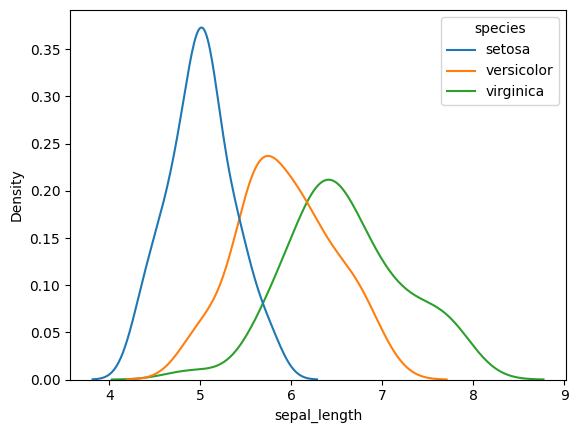

In [130]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

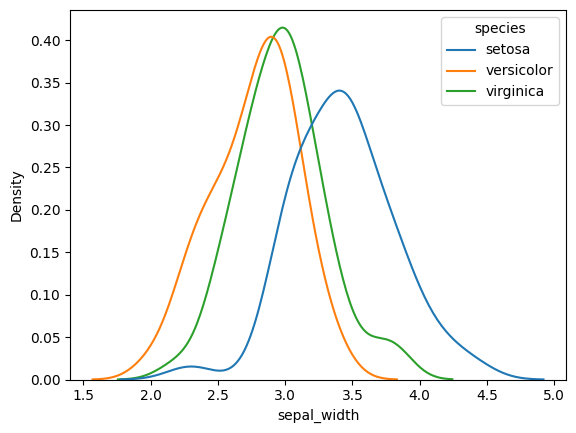

In [131]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

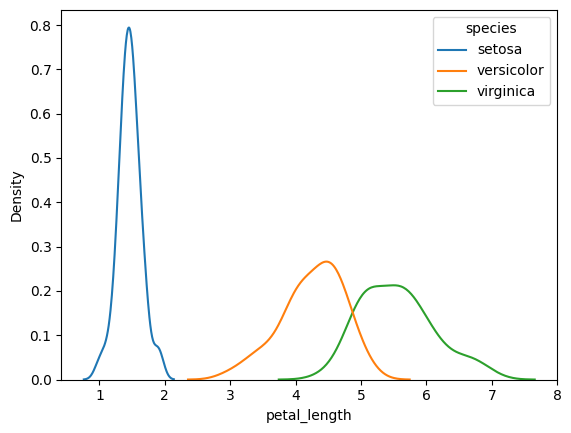

In [132]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

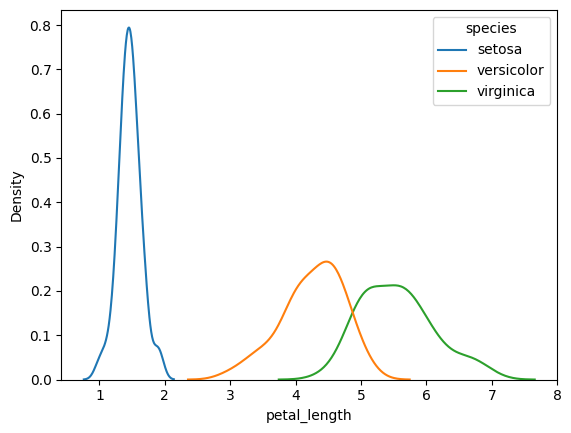

In [133]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [134]:
tips=sns.load_dataset("tips")

In [135]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

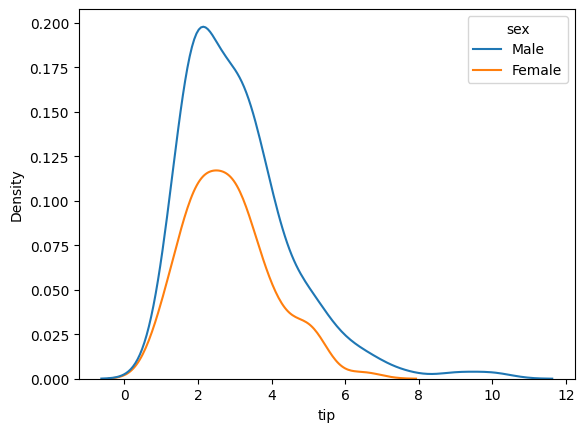

In [136]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

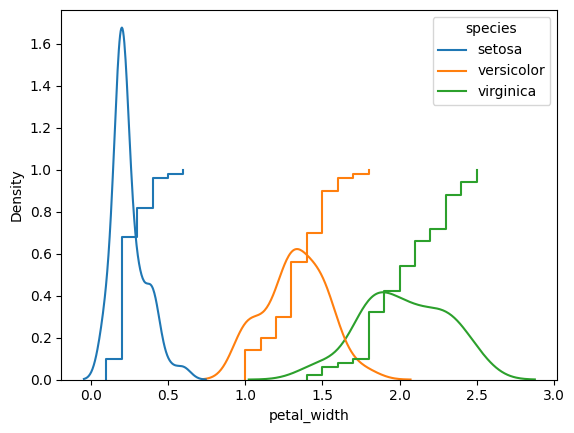

In [137]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [138]:
#contour plots

How to find distribution is normal or not?

In [139]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

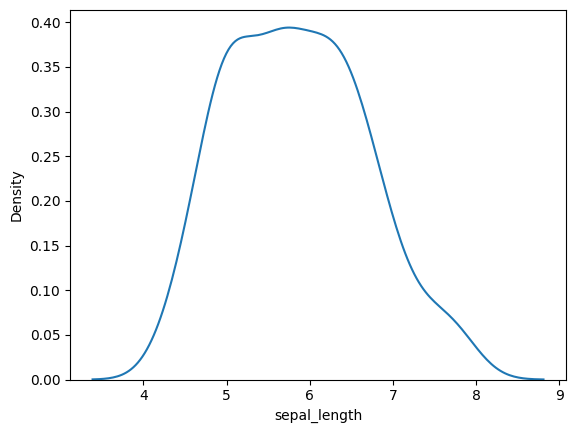

In [140]:
sns.kdeplot(iris["sepal_length"])

In [141]:
temp=sorted(iris['sepal_length'].tolist())

In [142]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [143]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [144]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

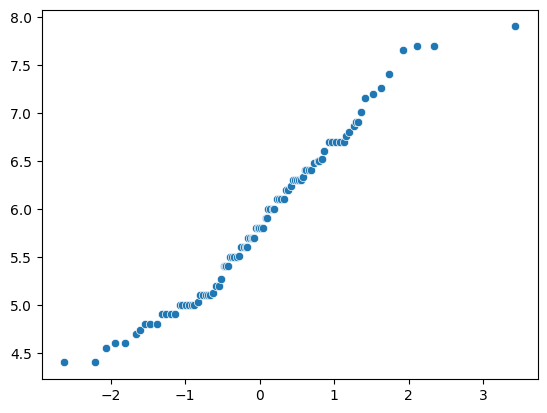

In [145]:
sns.scatterplot(x=x_quant,y=y_quant)

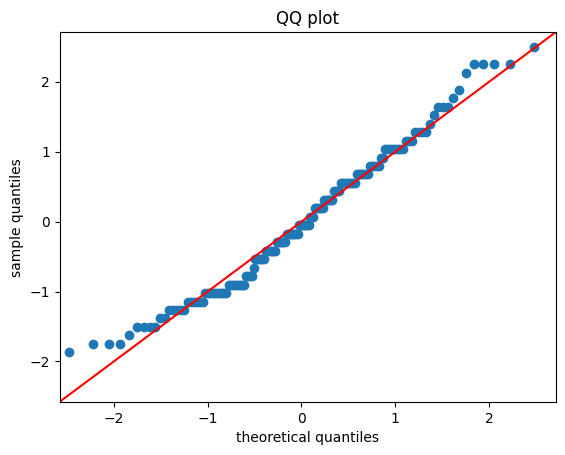

In [146]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [147]:
import scipy.stats as stats

In [148]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([100., 111.,  98., 117.,  96.,  83.,  96., 107.,  94.,  98.]),
 array([0.00129527, 0.10103389, 0.20077251, 0.30051112, 0.40024974,
        0.49998836, 0.59972698, 0.6994656 , 0.79920421, 0.89894283,
        0.99868145]),
 <BarContainer object of 10 artists>)

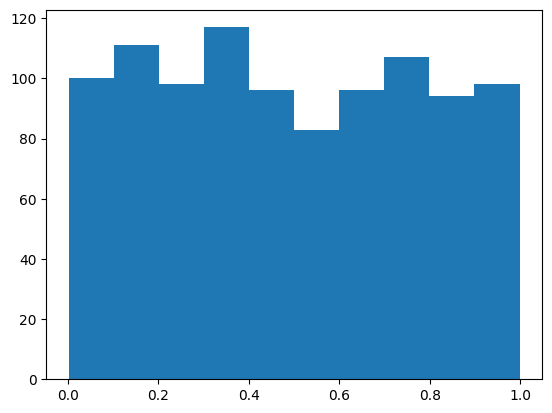

In [149]:
plt.hist(x)

PARETO DISTRIBUTION

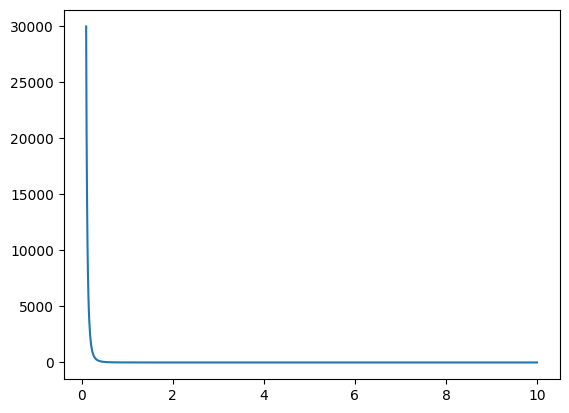

In [150]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

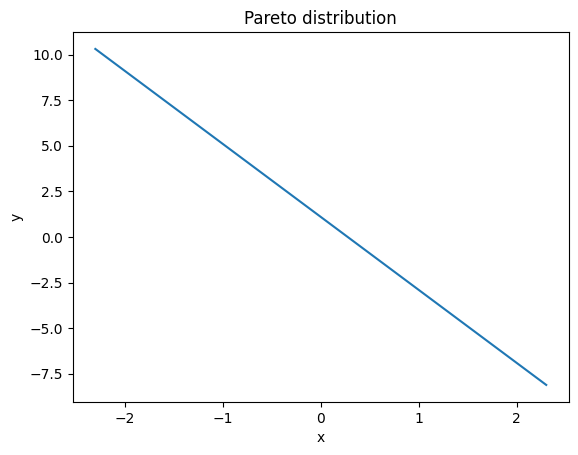

In [151]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [152]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([960.,  27.,   4.,   4.,   0.,   2.,   1.,   0.,   1.,   1.]),
 array([ 1.00017716,  5.00324955,  9.00632194, 13.00939434, 17.01246673,
        21.01553912, 25.01861151, 29.0216839 , 33.0247563 , 37.02782869,
        41.03090108]),
 <BarContainer object of 10 artists>)

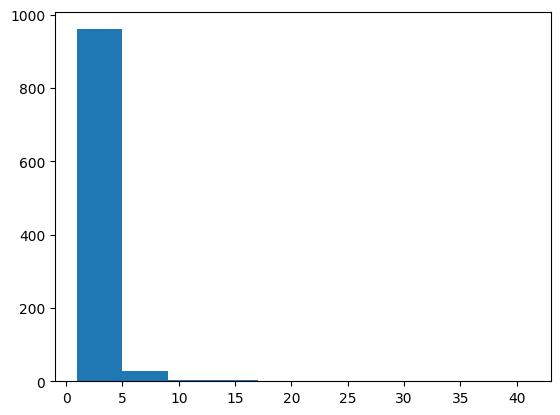

In [153]:
plt.hist(x)

In [154]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

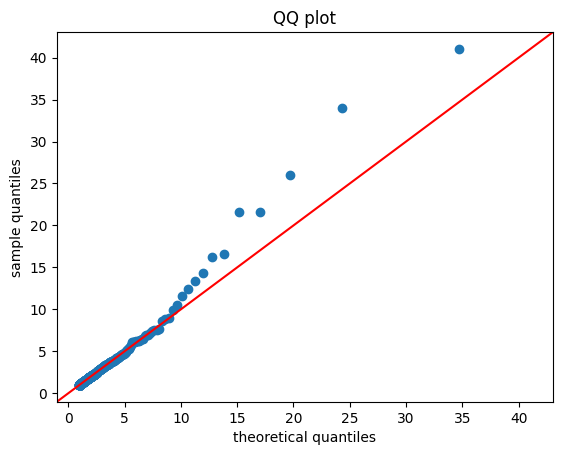

In [155]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [156]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [157]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [158]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [159]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [160]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [161]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_4240/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

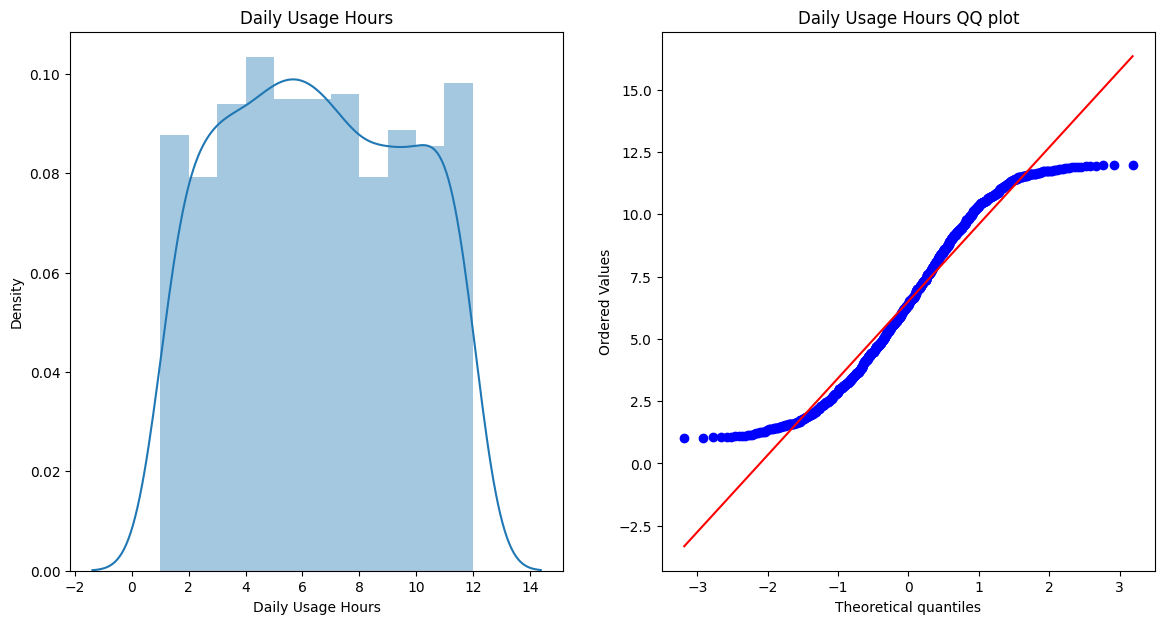

In [162]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

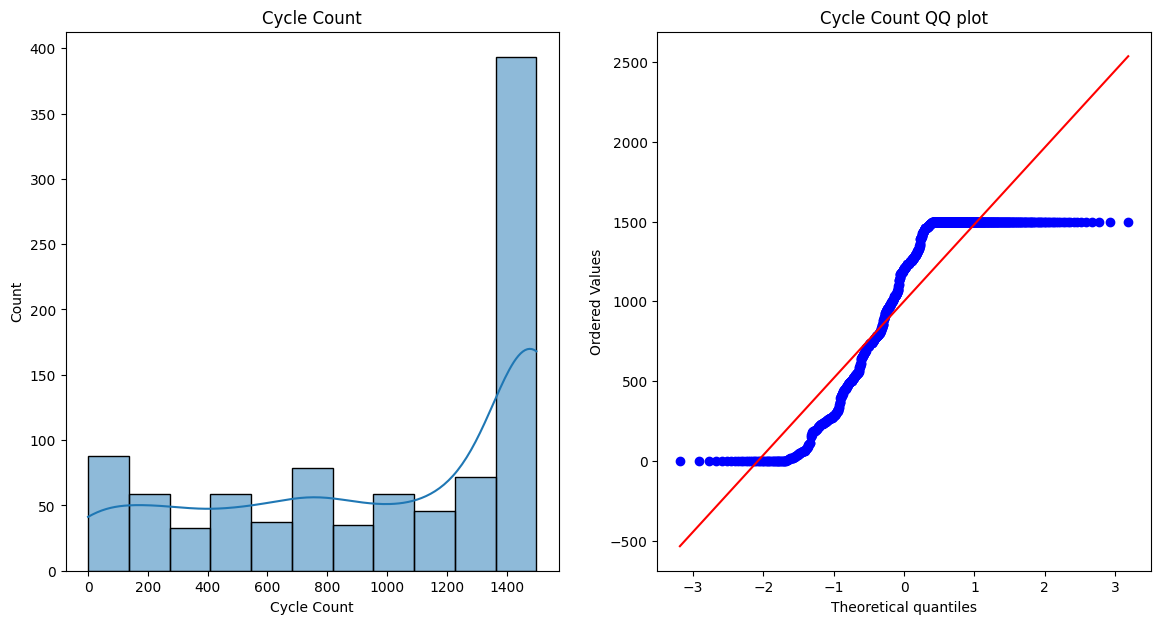

In [163]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [164]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [165]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [166]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [167]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [168]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.4708333333333333
Accuracy DT 0.7208333333333333


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [169]:
trf=FunctionTransformer(np.log1p)

In [170]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
668            1.425841     0.000000        11.141253     7.046647
74             1.125795     0.000000        10.783197     6.960348
727            1.078217     0.000000        10.726917     6.204558
500            2.519757     0.000000        11.007452     7.011214
1161           1.713961     0.000000        10.945459     7.313887
...                 ...          ...              ...          ...
885            1.888989     0.693147        11.274960     6.961296
1033           1.530651     0.000000        11.222119     7.312553
1084           2.161087     0.000000        11.106069     6.628041
535            1.968433     0.693147        11.076635     6.900731
447            1.662818     0.000000        10.826655     7.313887

[960 rows x 4 columns]
     Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
712           2.096776          0.0        10.903053     7.313887
222           1.258284          0.0     

In [171]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5041666666666667
Accuracy DT 0.7166666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 3  4  5  5  2  5  5  6  5  6  5  6  3  6  4  5  4  3  7  8  8  6  4  5
  5  3  5  5  5  5  2  4  6  3  6  7  4  7  7  4  5  6  2  7  5  4  3  6
  6  3  4  3  6  3  4  7  5  5  6  3  4  7  5  6  4  5  4  2  4  7  3  4
  7  5  4  4  6  5  4  5  4  5  4  7  5  5  4  6 10  3  3  3  4  4  5  5
  6  5  6  5  4  7  5  6  3  7  4  5  6  4  5  7  5  5  5  5  5  5  2  5
  3  4  8  7  5  4  6  9  4  5  5  4  6  4  7  1  4  5  6  7 10  7  3  9
  5  6  5  5  1  4  6  3  5  4  6  9  8  7  8  5  4  5  7  4  6  9  4  6
  4  4  4  5  6  7  5  4  7  5  4  6  7  4  5  8  4  7  5  5  7  3  6  5
  5  4  5  4  7  4  6  7  5  4  3  6  9  6  7  4  1  3  7  4  2  6  6  4
  4  7  7  2  3  7  7  2  6  7  9  3  4  5  5  6  6  6  5  5  5  6  6  5
  7  5  5  3  6  6  6  7  7  4  4  7  7  3  5  6  7  3  4  5  5  3  3  3
  6  6  7  6  5  4  6  5  3  6  7  4  4  5  6  6  5  5  6  6  8  7  6  6
  4  6  1  3  8  3  8  3  5  6  6  8  5  6  6  7  9  4  3  4  3  5  7  4
  4  7  8  5  5  2  6  5  8  5  4  4  5  6  7  4  7

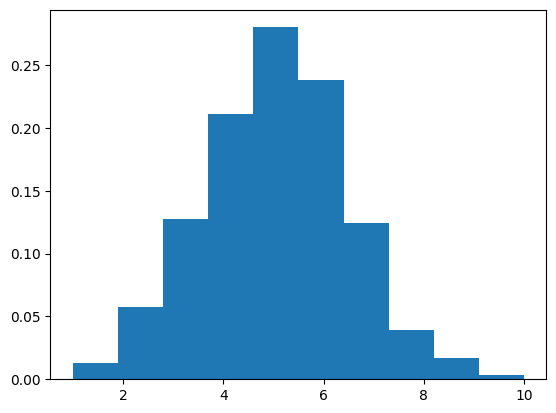

In [172]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [173]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [174]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.48288942, 0.48737296, 0.49874691, ..., 0.48424291, 0.52486611,
       0.50015469])

In [175]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

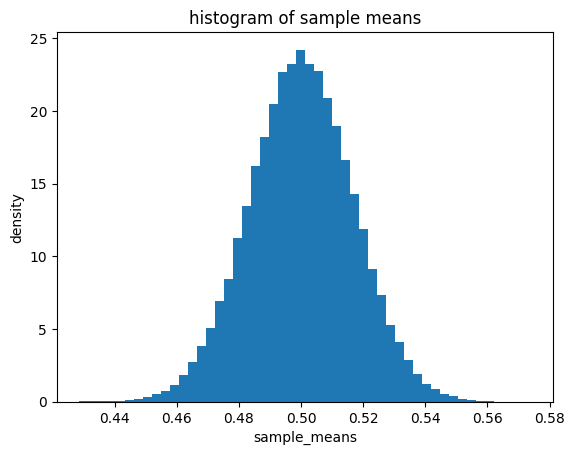

In [176]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [177]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

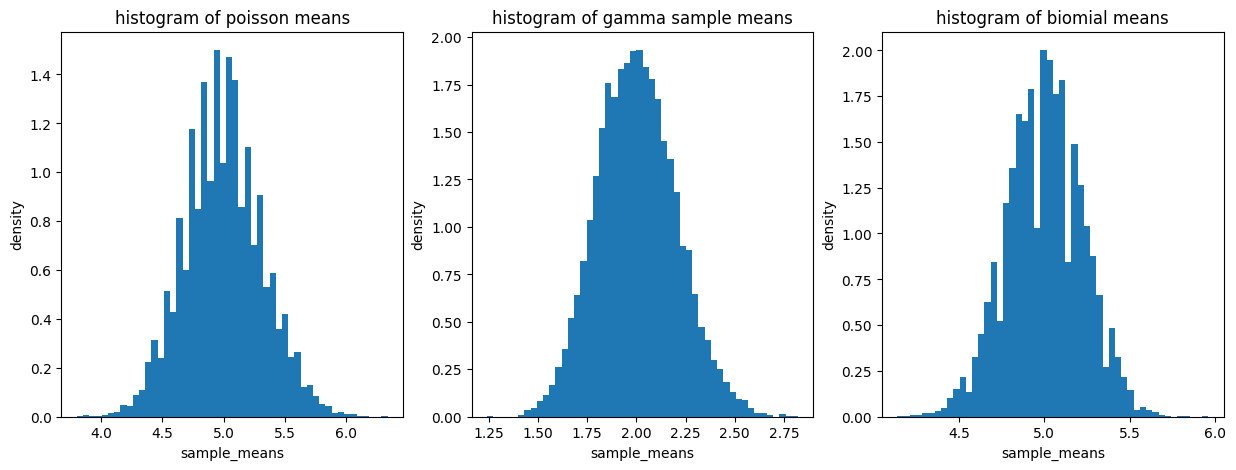

In [178]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [179]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 1.9956437147254786
Emperical variance: 0.06776811262146332


CASE STUDY

In [180]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [181]:
battery_csv.shape

(1200, 11)

In [182]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
819,9,11.831199,0,72079,1500,64.838983,48.224285,80.515837,33.244691,56217.528204,79.731221
357,4,7.549030,0,58275,1106,50.616346,30.887702,74.234404,29.478078,45781.923805,79.943058
528,8,4.298874,0,58936,1500,33.233736,19.530916,55.645915,28.769815,42317.887805,70.450722
666,3,6.888825,0,57780,688,57.741986,40.523659,67.963295,26.497551,50115.706109,85.627760
728,4,11.697075,0,54187,1010,73.445356,52.207727,99.278409,33.168100,44326.954352,83.203058
...,...,...,...,...,...,...,...,...,...,...,...
385,9,1.743652,0,64420,1500,22.652141,13.419789,37.997677,25.518755,49201.330766,75.771661
125,6,11.906861,0,76385,1500,70.393325,47.701210,83.753280,31.311651,62018.374287,80.657590
78,2,4.469001,0,75984,485,41.739687,30.027773,46.900866,28.990693,71802.733186,94.327775
309,8,2.851064,0,67258,1500,35.487379,27.932181,75.414668,31.024230,51852.032540,75.771306


In [183]:
d['Daily Usage Hours'].mean()

np.float64(6.435078131250979)

<Axes: ylabel='Density'>

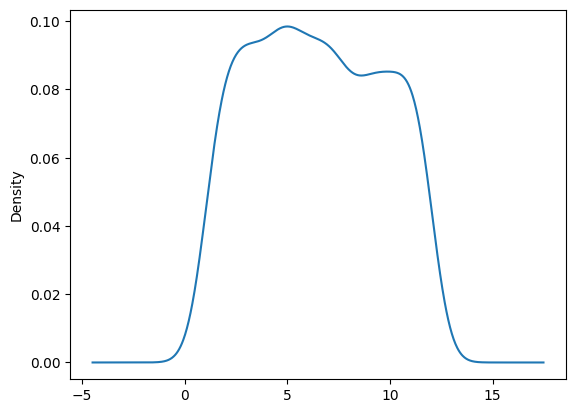

In [184]:
d['Daily Usage Hours'].plot(kind='density')

In [185]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
733,5.720644
881,10.727778
1079,7.341995
548,5.254880
797,9.429819
116,11.961789
908,10.492556
997,2.775925
81,2.066622
828,5.904081


In [186]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[8.411318527624989,
 10.851113149612734,
 2.598593616625545,
 10.21219771580652,
 10.655243453488874,
 9.428700200364167,
 4.9974432519936975,
 11.319992897771948,
 4.01386909416969,
 4.199645396547408,
 7.592956975463822,
 11.195983183604506,
 1.752847801668887,
 4.008219669124777,
 8.898155959397016,
 5.816898758572036,
 4.763458601230845,
 6.40121738935801,
 3.1528390410961395,
 11.729514044532197,
 10.015873565024094,
 7.09392581053444,
 10.871370501537449,
 3.658248129011037,
 3.2528264996183047,
 5.345586716424756,
 9.555007010745724,
 2.095376848940318,
 10.175805190292854,
 3.22523344074024,
 7.602765511095414,
 1.7484104550083666,
 2.195507933121613,
 6.325903353797482,
 3.9347400437721394,
 4.335417622286756,
 9.49367230377422,
 10.227392480944758,
 2.691620760645378,
 3.1194403613537034,
 2.857443097074345,
 3.874663196739221,
 10.75018398156156,
 9.845821214822726,
 4.1000750362501925,
 4.204971801215189,
 2.51937822454272,
 8.744345978508225,
 4.11612843841835,
 7.32566630

In [187]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [188]:
samples

[[10.175805190292854,
  3.704321867427403,
  4.6317154534716485,
  7.822583338572326,
  8.65687847723743,
  7.273156326045295,
  3.736709676130948,
  5.644114572687458,
  7.635699649524328,
  4.204971801215189,
  10.75018398156156,
  4.9974432519936975,
  5.909589959852173,
  5.847313717667229,
  3.733938030201686,
  4.524414147542364,
  6.735147236211153,
  11.632844429857183,
  4.44117617276642,
  11.019088911549469,
  8.644671464336234,
  10.15872950658744,
  5.605646576604526,
  6.068069602658412,
  3.033222377417274,
  7.241300385716807,
  6.063909104483096,
  7.353743887008471,
  7.34199488946254,
  7.017498801771355,
  10.307366315832548,
  3.6211863760840073,
  5.217368551640848,
  6.335197862764454,
  9.157900161970778,
  1.1524834950414613,
  10.566146532933884,
  3.246663170052717,
  8.381142785862007,
  4.8170256895342,
  1.10901765040269,
  11.622028727934804,
  9.429819344151175,
  8.28545112603792,
  10.445679333690313,
  6.230232867560071,
  7.584192925395359,
  5.71186

In [189]:
samples=np.array(samples)
samples

array([[10.17580519,  3.70432187,  4.63171545, ...,  5.71186981,
         8.02859324, 11.63998309],
       [ 4.77603038,  1.90829374,  1.58109355, ...,  9.27325766,
         6.58533622,  5.32999072],
       [10.3933717 ,  9.13416157,  6.36995443, ...,  4.90277019,
         9.4287002 ,  6.38764455],
       ...,
       [11.26154459,  9.73415895,  6.98683071, ...,  6.3479102 ,
         4.76033946, 11.79383335],
       [ 3.35394147,  2.99939958,  2.56812211, ...,  6.80346771,
         4.68366119,  2.84596055],
       [ 3.48368507,  7.35374389,  3.47123137, ...,  1.26340892,
        11.00923174,  4.93592374]])

In [190]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [191]:
sampling_means.mean()

np.float64(6.4449260216321695)

In [192]:
sampling_means.std()/np.sqrt(50)

np.float64(0.05835357129990982)

<Axes: ylabel='Density'>

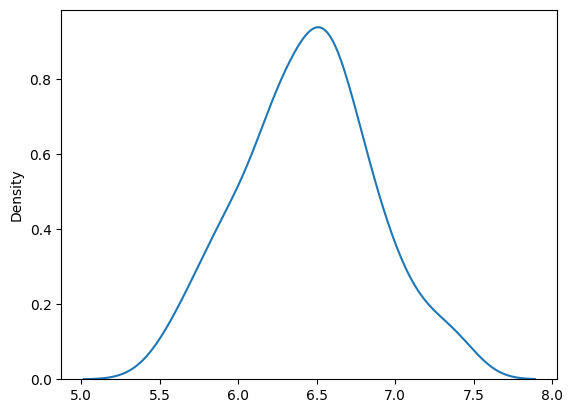

In [193]:
sns.kdeplot(data=sampling_means)

In [194]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.32821887903235 - 6.561633164231989


t-test

In [195]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [196]:
train=df.drop(columns=['Battery Health'])
test=df['Battery Health']

In [197]:
final=pd.concat([train,test]).sample(1000)

In [198]:
corr = df.corr(numeric_only=True)['Battery Health'].drop(
    'Battery Health'
)
print(corr)

Battery Age            -0.900723
Daily Usage Hours      -0.084347
Gaming User             0.018509
Design Capacity         0.289450
Cycle Count            -0.921454
CPU Usage              -0.052363
GPU Usage              -0.033122
Power Consumption      -0.048988
Average Temperature    -0.041134
Full Charge Capacity    0.704030
Name: Battery Health, dtype: float64


In [199]:
meanf=np.mean(df['Full Charge Capacity'])
print(meanf)

51798.12594357623


In [200]:
#H_0:u=51798.13
#H_a:u!=51798.13

In [201]:
vals=final['Full Charge Capacity'].dropna()

In [202]:
sample_vals=vals.sample(200).values
sample_vals

array([76282.0825638 , 66966.8787723 , 57309.38388425, 64091.30963426,
       47274.96891328, 62730.17647938, 34721.42432428, 36027.31577971,
       50622.7946499 , 36046.48450777, 54397.97160882, 71407.93946973,
       69246.70841393, 57646.33093843, 45781.92380497, 51883.00069462,
       63057.06423949, 41598.17444804, 57742.79487009, 60985.25623274,
       40951.08966951, 35458.03854481, 59616.35739397, 28966.79020963,
       65358.24927449, 54360.15736121, 34244.98670708, 68577.63063474,
       30314.26657043, 46882.99785375, 58508.62663804, 37989.42353322,
       70988.93514609, 43334.54796204, 62561.61893359, 71054.07703489,
       72461.96667133, 61546.33363624, 50026.56884415, 40559.39144197,
       48363.85278123, 74908.824137  , 52086.        , 36982.74925413,
       66627.02892623, 49312.81468978, 30072.71411356, 52566.25548105,
       53107.00951384, 58373.03698266, 36066.87093465, 54119.97033876,
       72191.87526442, 44197.50254738, 35467.11014152, 33427.87418275,
      

In [203]:
mean_s=np.mean(sample_vals)
print(mean_s)
std_s=np.std(sample_vals)
print(std_s)

51726.27577029073
12274.563658504807


In [204]:
#check normality using shapiro wilk test
from scipy.stats import shapiro

shapiro_s=shapiro(sample_vals)
print(shapiro_s)

ShapiroResult(statistic=np.float64(0.9799520273850417), pvalue=np.float64(0.0058555544723235126))


In [205]:
import scipy.stats as stats

t_statistics,p_value=stats.ttest_1samp(sample_vals,50000)
print(t_statistics,p_value/2)


1.983949669991944 0.024318014896557827


INDEPENDENT 2SAMPLE T-TEST

In [206]:
url="https://raw.githubusercontent.com/SUCCESSneeded/practice/refs/heads/main/E%20Commerce%20Dataset%20(1).csv"
df2=pd.read_csv(url)
print(df2.head())
df2.shape

   CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0       50001      1     4.0         Mobile Phone         3              6.0   
1       50002      1     NaN                Phone         1              8.0   
2       50003      1     NaN                Phone         1             30.0   
3       50004      1     0.0                Phone         3             15.0   
4       50005      1     0.0                Phone         1             12.0   

  PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0           Debit Card  Female             3.0                         3   
1                  UPI    Male             3.0                         4   
2           Debit Card    Male             2.0                         4   
3           Debit Card    Male             2.0                         4   
4                   CC    Male             NaN                         3   

     PreferedOrderCat  SatisfactionScore MaritalStatus  Number

(5630, 20)

In [207]:
churn=df2.dropna()
print(churn.head())
churn.shape

    CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  WarehouseToHome  \
0        50001      1     4.0         Mobile Phone         3              6.0   
3        50004      1     0.0                Phone         3             15.0   
5        50006      1     0.0             Computer         1             22.0   
11       50012      1    11.0         Mobile Phone         1              6.0   
12       50013      1     0.0                Phone         1             11.0   

   PreferredPaymentMode  Gender  HourSpendOnApp  NumberOfDeviceRegistered  \
0            Debit Card  Female             3.0                         3   
3            Debit Card    Male             2.0                         4   
5            Debit Card  Female             3.0                         5   
11           Debit Card    Male             3.0                         4   
12                  COD    Male             2.0                         3   

      PreferedOrderCat  SatisfactionScore MaritalS

(3774, 20)

In [208]:
churn.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,160
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134
5,50006,1,0.0,Computer,1,22.0,Debit Card,Female,3.0,5,Mobile Phone,5,Single,2,1,22.0,4.0,6.0,7.0,139
11,50012,1,11.0,Mobile Phone,1,6.0,Debit Card,Male,3.0,4,Fashion,3,Single,10,1,13.0,0.0,1.0,0.0,154
12,50013,1,0.0,Phone,1,11.0,COD,Male,2.0,3,Mobile,3,Single,2,1,13.0,2.0,2.0,2.0,134


In [209]:
corr = df2.corr(numeric_only=True)['CashbackAmount'].drop(
    'CashbackAmount'
)
print(corr)

CustomerID                     0.217173
Churn                         -0.154161
Tenure                         0.476577
CityTier                       0.055698
WarehouseToHome               -0.009536
HourSpendOnApp                 0.121469
NumberOfDeviceRegistered       0.137396
SatisfactionScore              0.003429
NumberOfAddress                0.186802
Complain                       0.000598
OrderAmountHikeFromlastYear    0.017961
CouponUsed                     0.286391
OrderCount                     0.360527
DaySinceLastOrder              0.346777
Name: CashbackAmount, dtype: float64


In [210]:
mobile_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Phone", case=False, na=False
    )
].copy()

# Dataset for computers and laptops
computer_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Laptop|Computer", case=False, na=False, regex=True
    )
].copy()

print("Mobile dataset:", mobile_df.shape)
print("Computer dataset:", computer_df.shape)
print(mobile_df)

Mobile dataset: (1227, 20)
Computer dataset: (1961, 20)
      CustomerID  Churn  Tenure PreferredLoginDevice  CityTier  \
5          50006      1     0.0             Computer         1   
19         50020      1    19.0         Mobile Phone         1   
25         50026      1     0.0                Phone         1   
50         50051      0    29.0                Phone         1   
52         50053      1     0.0         Mobile Phone         1   
...          ...    ...     ...                  ...       ...   
5615       55616      0    14.0         Mobile Phone         1   
5617       55618      0    14.0                Phone         1   
5618       55619      0     9.0         Mobile Phone         1   
5620       55621      0     3.0         Mobile Phone         1   
5624       55625      0     1.0         Mobile Phone         3   

      WarehouseToHome PreferredPaymentMode  Gender  HourSpendOnApp  \
5                22.0           Debit Card  Female             3.0   
19         

In [211]:
mobile_sample=mobile_df.sample(100)
computer_sample=computer_df.sample(100)

print(mobile_sample.shape)
print(computer_sample.shape)

(100, 20)
(100, 20)


(array([ 1.,  0.,  0.,  0., 17., 25., 32., 13.,  9.,  3.]),
 array([111. , 117.2, 123.4, 129.6, 135.8, 142. , 148.2, 154.4, 160.6,
        166.8, 173. ]),
 <BarContainer object of 10 artists>)

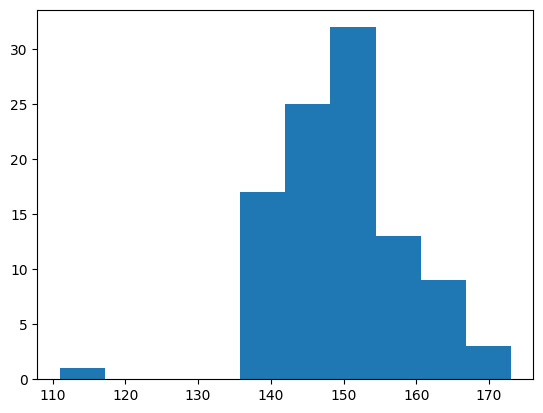

In [212]:
plt.hist(mobile_sample['CashbackAmount'])

In [213]:
mobile_smean=np.mean(mobile_sample['CashbackAmount'])
mobile_sstd=np.std(mobile_sample['SatisfactionScore'])

computer_smean=np.mean(computer_sample['CashbackAmount'])
computer_sstd=np.std(computer_sample['CashbackAmount'])
print(mobile_smean,mobile_sstd)
print(computer_smean,computer_sstd)

150.13 1.512448346225418
167.12 16.135848288825724


In [214]:
from sklearn.preprocessing import PowerTransformer
from scipy.stats import shapiro

# Create transformer
pt = PowerTransformer(method='yeo-johnson', standardize=True)
# Transform mobile sample
mobile_sample['CashbackAmount_normal'] = pt.fit_transform(
    mobile_sample[['CashbackAmount']]
)

# Transform computer sample using its own fitted transformer
pt2 = PowerTransformer(method='yeo-johnson', standardize=True)

computer_sample['CashbackAmount_normal'] = pt2.fit_transform(
    computer_sample[['CashbackAmount']]
)

print("Mobile:", shapiro(mobile_sample['CashbackAmount_normal']))
print("Computer:", shapiro(computer_sample['CashbackAmount_normal']))

Mobile: ShapiroResult(statistic=np.float64(0.9664243789635124), pvalue=np.float64(0.011851930588614565))
Computer: ShapiroResult(statistic=np.float64(0.9661310385693517), pvalue=np.float64(0.011268526625946934))


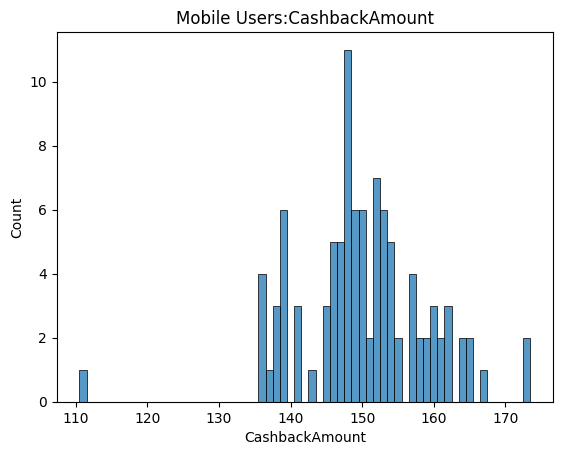

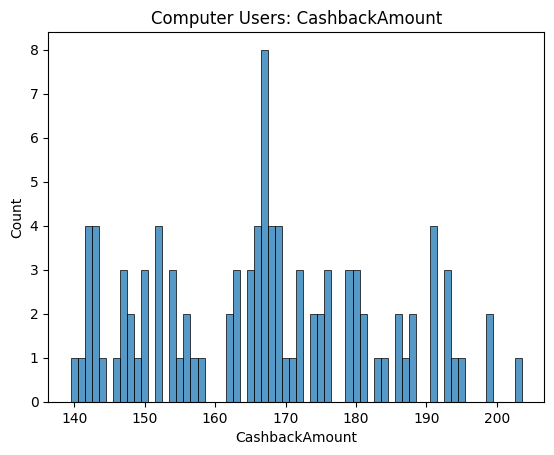

In [215]:
sns.histplot(mobile_sample["CashbackAmount"], discrete=True)
plt.title("Mobile Users:CashbackAmount")
plt.show()

sns.histplot(computer_sample["CashbackAmount"], discrete=True)
plt.title("Computer Users: CashbackAmount")
plt.show()

In [216]:
from scipy.stats import levene

l_test=levene(mobile_sample['CashbackAmount'],computer_sample['CashbackAmount'])
print(l_test)
'''pvalue > 0.05 therefor popvarP==popvarC'''

LeveneResult(statistic=np.float64(31.832188177323808), pvalue=np.float64(5.7532398046457795e-08))


'pvalue > 0.05 therefor popvarP==popvarC'

In [217]:
from scipy.stats import t
t_val=6.31
dof=198
cdf_val=t.cdf(t_val,dof)
print(cdf_val*2)

1.9999999982097374


PAIRED SAMPLE T-TEST

In [225]:
Weight_Before=np.array([81, 94, 89, 82, 95, 93, 97, 85, 85, 98, 77, 96, 77, 98, 86])
Weight_After=np.array([75, 89, 83, 74, 90, 88, 94, 81, 80, 93, 71, 91, 71, 91, 83])

differences=Weight_After-Weight_Before

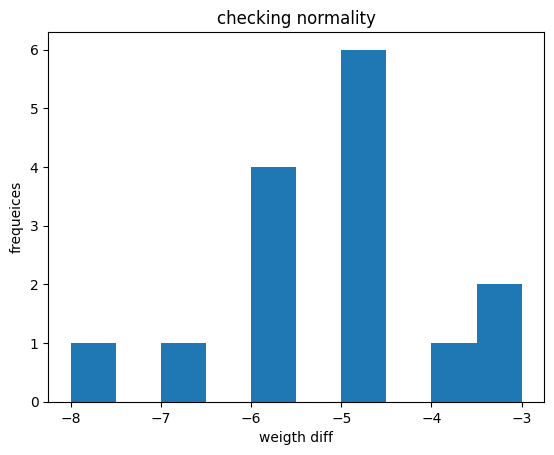

ShapiroResult(statistic=np.float64(0.9271418226628616), pvalue=np.float64(0.24721333614729252))


In [226]:
plt.hist(differences)
plt.title("checking normality")
plt.xlabel("weigth diff")
plt.ylabel("frequeices")
plt.show()
shapirotest=stats.shapiro(differences)
print(shapirotest)

In [230]:
diff_m=np.mean(differences)
diff_s=np.std(differences,ddof=1)
print(diff_m,diff_s)

-5.266666666666667 1.3345232785352157


In [231]:
n=len(differences)
t_val=diff_m/(diff_s/np.sqrt(n))
print(t_val)
dof=n-1


-15.284643301549925


In [234]:
alpha=0.05
pval=1-t.cdf(t_val,dof)
print(pval)

0.9999999998016127
